
# ДЗ №1. Разведочный анализ сетевого трафика для выявления признаков кибератак

**Дисциплина:** Программные инструменты анализа данных в задачах информационной безопасности, Осень 2026

**Выполнил:** Татарнев Павел Павлович

**Группа:** РИ - 431001

**Тема:** Разведочный анализ сетевого трафика для выявления признаков кибератак

**Цель работы:** Постановка задачи машинного обучения, выбор метрик качества и проведение разведочного анализа данных (EDA).


# 1. Постановка задачи

## 1.1. Бизнес-постановка задачи

Корпоративные компьютерные сети подвергаются различным кибератакам, направленным на нарушение доступности информационных ресурсов, получение несанкционированного доступа и компрометацию данных.

Цель проекта – исследовать характеристики сетевого трафика для выявления признаков, позволяющих отличать нормальные сетевые соединения от соединений, связанных с кибератаками.

Результаты исследования могут использоваться для последующей разработки модели машинного обучения, способной автоматически классифицировать сетевой трафик и помогать системам обнаружения вторжений (IDS) выявлять потенциально опасную активность.




## 1.2. Постановка задачи машинного обучения

Задача обнаружения сетевых атак формулируется как задача бинарной классификации (Binary Classification) с учителем (Supervised Learning).

На вход модели поступает набор признаков, характеризующих сетевое соединение: используемый протокол, продолжительность соединения, количество переданных байтов и пакетов, а также другие сетевые характеристики.

На основании этих признаков модель должна определить принадлежность соединения к одному из двух классов:

- **0 – нормальный сетевой трафик;**
- **1 – сетевой трафик, связанный с атакой.**

Объект классификации – запись о сетевом соединении.

Признаки (Features) – характеристики сетевого соединения, используемые для классификации.

Целевая переменная (Target) – бинарная метка `label`, указывающая на наличие или отсутствие атаки.

Для решения задачи планируется использовать набор данных UNSW-NB15, содержащий размеченные примеры нормального и атакующего сетевого трафика.



## 1.3. Описание набора данных

Для исследования выбран набор данных **UNSW-NB15**, разработанный Университетом Нового Южного Уэльса (Австралия) для изучения методов обнаружения сетевых вторжений.

**Источник:** https://research.unsw.edu.au/projects/unsw-nb15-dataset

Датасет содержит характеристики нормального сетевого трафика и трафика, связанного с девятью категориями кибератак, включая DoS, Reconnaissance, Exploits и другие.

Полный набор содержит 2 540 044 записи. Для выполнения работы используется подготовленная обучающая выборка `UNSW_NB15_training-set.csv`, включающая 175 341 запись и 45 столбцов, в том числе идентификатор записи и метки классов.

Основные рассматриваемые признаки:

- `proto` – используемый сетевой протокол;
- `dur` – продолжительность соединения;
- `sbytes` – количество переданных байтов от источника;
- `dbytes` – количество переданных байтов получателю в обратном направлении;
- `spkts` – количество пакетов от источника;
- `service` – используемый прикладной сервис;
- `state` – состояние сетевого соединения.

Целевая переменная `label` содержит два класса:

- `0` – нормальный сетевой трафик;
- `1` – трафик, связанный с атакой.

Дополнительный столбец `attack_cat` указывает категорию атаки и может использоваться для исследования распределения атак, но не должен применяться как входной признак для предсказания `label`.

Набор данных подходит для постановки задачи бинарной классификации, поскольку содержит размеченные примеры обоих классов и характеристики сетевых соединений.

Ограничение датасета – данные получены в лабораторной среде и опубликованы в 2015 году, поэтому выявленные закономерности могут не полностью отражать современный сетевой трафик.


# 2. Выбор и обоснование метрик качества.

## 2.1. Выбор метрик качества

Для оценки качества будущей модели обнаружения сетевых атак выбраны следующие метрики:

- **Recall (полнота)** – доля правильно обнаруженных атак среди всех реальных атак.
- **Precision (точность положительных предсказаний)** – доля правильно обнаруженных атак среди всех соединений, классифицированных моделью как атаки.
- **FPR (False Positive Rate)** – доля нормальных соединений, ошибочно классифицированных как атакующие.

Основной метрикой выбрана полнота (Recall) при контролируемом уровне FPR, поскольку пропуск сетевой атаки может привести к инциденту информационной безопасности. При этом необходимо ограничивать количество ложных срабатываний, чтобы избежать чрезмерной нагрузки на аналитиков SOC.



# 3. Разведочный анализ данных (EDA)

## 3.1. Загрузка и первичный просмотр данных

На первом этапе разведочного анализа загрузим датасет UNSW-NB15 с помощью библиотеки pandas и рассмотрим его структуру.

Для загрузки используется функция `read_csv()`, которая считывает данные из CSV-файла в объект DataFrame. С помощью метода `head()` выведем первые пять записей для первоначального ознакомления с данными.


In [13]:

import pandas as pd
import requests
from pathlib import Path

# Путь для сохранения датасета
data_path = Path("UNSW_NB15_training-set.csv")


# Ссылка на датасет
url = "https://huggingface.co/datasets/Mouwiya/UNSW-NB15/resolve/8ad6b19373f143086a66f52b0d6035a6959d83a9/UNSW_NB15_training-set.csv"

# Скачиваем файл, если его ещё нет
if not data_path.exists():
    print("Скачивание датасета...")
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    data_path.write_bytes(response.content)

# Загружаем данные
df = pd.read_csv(data_path)

print("Размер датасета:", df.shape)
display(df.head())


Размер датасета: (175341, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0



## 3.2. Исследование структуры датасета

Для первоначального анализа определим размер набора данных, типы признаков и основные статистические характеристики числовых столбцов.


In [3]:

print("Размер датасета:", df.shape)

print("\nИнформация о столбцах:")
df.info()

print("\nОписательная статистика:")
display(df.describe())


Размер датасета: (175341, 45)

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 1

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000



**Выводы по первичному анализу данных:**

Исследуемый набор данных содержит 175 341 запись и 45 столбцов, из которых 41 имеет числовой тип, а 4 – тип `object`.

Анализ описательных статистик показал значительные различия между средними значениями и медианами некоторых сетевых характеристик. Например, средняя продолжительность соединения составляет около 1,36 секунды, тогда как медианная – 0,001582 секунды. Это указывает на асимметричность распределения и необходимость дополнительного исследования возможных выбросов.

Аналогичные различия наблюдаются для количества переданных байтов (`sbytes`, `dbytes`). При дальнейшем анализе целесообразно использовать визуализации распределений, в том числе с логарифмическим преобразованием.

Среднее значение бинарной целевой переменной `label` составляет 0,6806, что соответствует приблизительно 68,06% записей атакующего трафика. Таким образом, в обучающей выборке наблюдается дисбаланс классов, который необходимо учитывать при последующей разработке модели.

Проверка пропущенных значений, дубликатов и других проблем качества данных будет проведена отдельно.



## 3.3. Проверка качества данных

На данном этапе проверим набор данных на наличие пропущенных значений и дубликатов. Дополнительно исследуем особенности представления отсутствующих значений в категориальных признаках.


In [4]:

# Проверка пропущенных значений
print("Общее количество пропущенных значений:")
print(df.isna().sum().sum())

print("\nПропуски по столбцам:")
print(df.isna().sum())

# Проверка полных дубликатов
print("\nПолные дубликаты:")
print(df.duplicated().sum())

# Проверка дубликатов без идентификатора id
print("\nДубликаты без учета id:")
print(df.drop(columns=["id"]).duplicated().sum())


Общее количество пропущенных значений:
0

Пропуски по столбцам:
id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm      


**Выводы по проверке качества данных:**

Проверка датасета UNSW-NB15 не выявила пропущенных значений (`NaN`). Все 175 341 записи содержат значения во всех столбцах.

При проверке полных дубликатов совпадающих строк не обнаружено, поскольку столбец `id` содержит уникальные идентификаторы записей.

После исключения `id` выявлено 67 601 повторение, что составляет приблизительно 38,6% от общего количества записей.

Наличие большого количества повторений требует дополнительного исследования. Одинаковые значения признаков не обязательно означают ошибку, поскольку разные сетевые соединения могут иметь одинаковые характеристики. Однако такие повторения способны влиять на обучение и оценку качества модели.

На данном этапе дубликаты не удаляются. В дальнейшем необходимо учитывать возможность попадания одинаковых записей в обучающую и тестовую выборки.

Дополнительно требуется проверить категориальные признаки на наличие специальных обозначений отсутствующих или неопределённых значений, например `"-"`.



## 3.4. Исследование распределения классов

Исследуем соотношение нормального и атакующего сетевого трафика в обучающей выборке UNSW-NB15.

Для этого рассчитаем абсолютное и относительное количество записей каждого класса и построим столбчатую диаграмму с использованием библиотек matplotlib и seaborn.


Количество записей по классам:
label
0     56000
1    119341
Name: count, dtype: int64

Доля каждого класса (%):
label
0    31.94
1    68.06
Name: proportion, dtype: float64


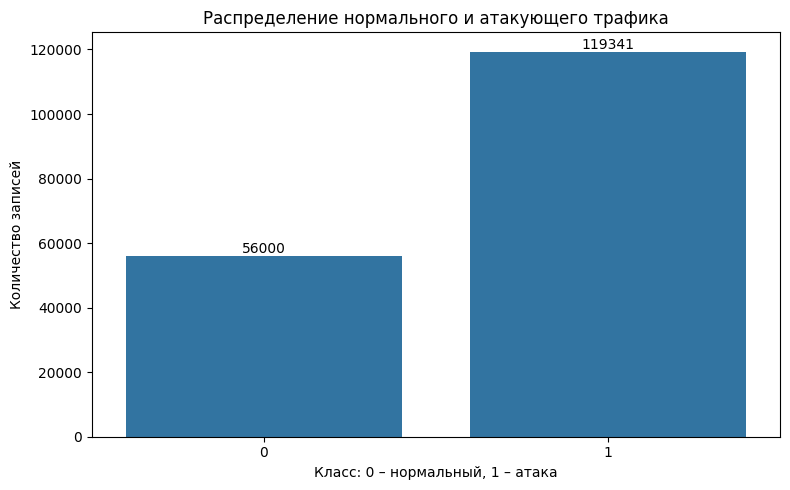

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

# Количество записей каждого класса
class_counts = df["label"].value_counts().sort_index()

print("Количество записей по классам:")
print(class_counts)

# Процентное соотношение классов
class_percent = df["label"].value_counts(normalize=True).sort_index() * 100

print("\nДоля каждого класса (%):")
print(class_percent.round(2))

# Построение графика
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="label", order=[0, 1])

ax.set_title("Распределение нормального и атакующего трафика")
ax.set_xlabel("Класс: 0 – нормальный, 1 – атака")
ax.set_ylabel("Количество записей")

# Подписываем количество записей над столбцами
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()



**Выводы по распределению классов:**

Анализ обучающей выборки UNSW-NB15 показал, что из 175 341 записи 119 341 (68,06%) относятся к атакующему трафику, а 56 000 (31,94%) – к нормальному.

Таким образом, наблюдается дисбаланс классов: атакующий трафик представлен приблизительно в 2,13 раза чаще нормального.

Подобное распределение может влиять на обучение и оценку качества классификатора. Использование одной только метрики Accuracy не позволяет полноценно оценивать способность модели обнаруживать атаки без чрезмерного количества ложных срабатываний.

При последующем обучении необходимо учитывать соотношение классов и использовать ранее выбранные метрики Recall, Precision и FPR.

Следует также учитывать, что распределение классов в лабораторном датасете не отражает реальную распространённость атак в корпоративных сетях.



## 3.5. Анализ категорий сетевых атак

Датасет UNSW-NB15 содержит дополнительный признак `attack_cat`, определяющий категорию сетевой атаки.

Исследуем распределение различных категорий атак, чтобы определить наиболее распространённые и редко встречающиеся типы атак в обучающей выборке.


,Количество,Доля среди атак (%)
attack_cat,,
Generic,40000,33.52
Exploits,33393,27.98
Fuzzers,18184,15.24
DoS,12264,10.28
Reconnaissance,10491,8.79
Analysis,2000,1.68
Backdoor,1746,1.46
Shellcode,1133,0.95
Worms,130,0.11


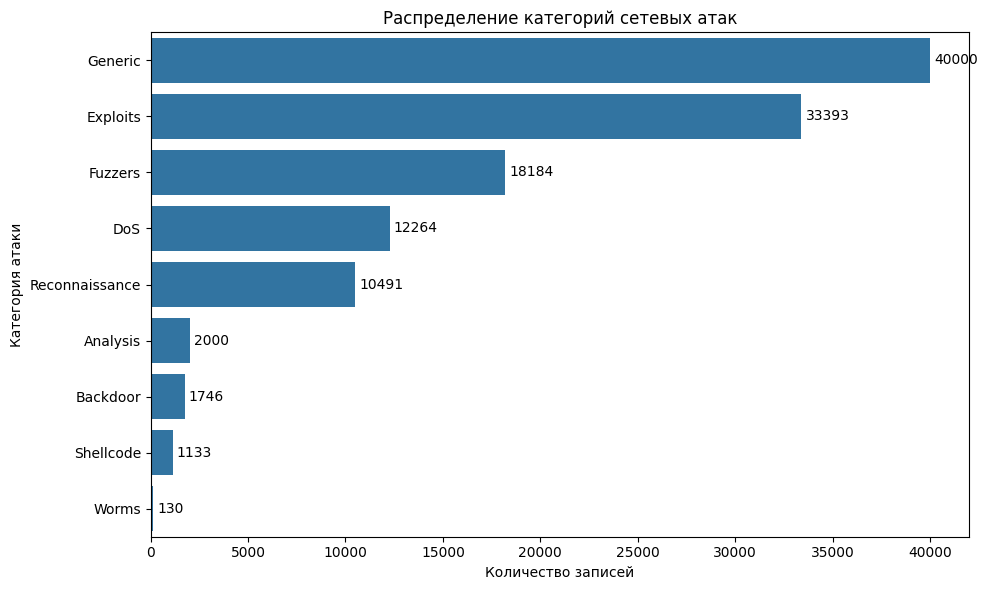

In [6]:

# Оставляем только записи с атаками
attack_df = df[df["label"] == 1]

# Подсчитываем количество атак по категориям
attack_counts = attack_df["attack_cat"].value_counts()

# Создаём таблицу с количеством и процентами
attack_stats = pd.DataFrame({
    "Количество": attack_counts,
    "Доля среди атак (%)": (
        attack_counts / len(attack_df) * 100
    ).round(2)
})

display(attack_stats)

# Строим график
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=attack_df,
    y="attack_cat",
    order=attack_counts.index
)

ax.set_title("Распределение категорий сетевых атак")
ax.set_xlabel("Количество записей")
ax.set_ylabel("Категория атаки")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()



**Выводы по анализу категорий сетевых атак:**

Анализ столбца `attack_cat` показал, что в обучающей выборке UNSW-NB15 представлены девять категорий сетевых атак с существенно различающимся количеством записей.

Наиболее распространёнными категориями являются `Generic` (40 000 записей, 33,52%) и `Exploits` (33 393 записи, 27,98%). Совместно они составляют около 61,5% всего атакующего трафика.

Наименее представленной категорией является `Worms` – всего 130 записей (0,11%). Это свидетельствует о значительном дисбалансе между отдельными категориями атак.

Неравномерное распределение может повлиять на обучение будущего классификатора: модель потенциально будет лучше распознавать категории с большим количеством обучающих примеров, тогда как редкие категории могут обнаруживаться хуже.

Поэтому при последующей оценке модели целесообразно дополнительно анализировать полноту обнаружения (Recall) отдельно для каждой категории атак.

Столбец `attack_cat` используется исключительно для разведочного анализа и не должен включаться во входные признаки бинарного классификатора, поскольку содержит информацию, непосредственно связанную с целевой переменной `label`.



## 3.6. Анализ сетевых протоколов

Исследуем распределение сетевых протоколов, представленных в столбце `proto`.

Для десяти наиболее распространённых протоколов определим количество записей и долю атакующего трафика. Это позволит оценить возможную связь используемого протокола с целевой переменной `label`.


,total,attacks,attack_percent
proto,,,
tcp,79946,40825,51.07
udp,63283,49361,78.00
unas,12084,12084,100.00
arp,2859,0,0.00
ospf,2595,2531,97.53
sctp,1150,1150,100.00
any,300,300,100.00
gre,225,225,100.00
mobile,201,201,100.00


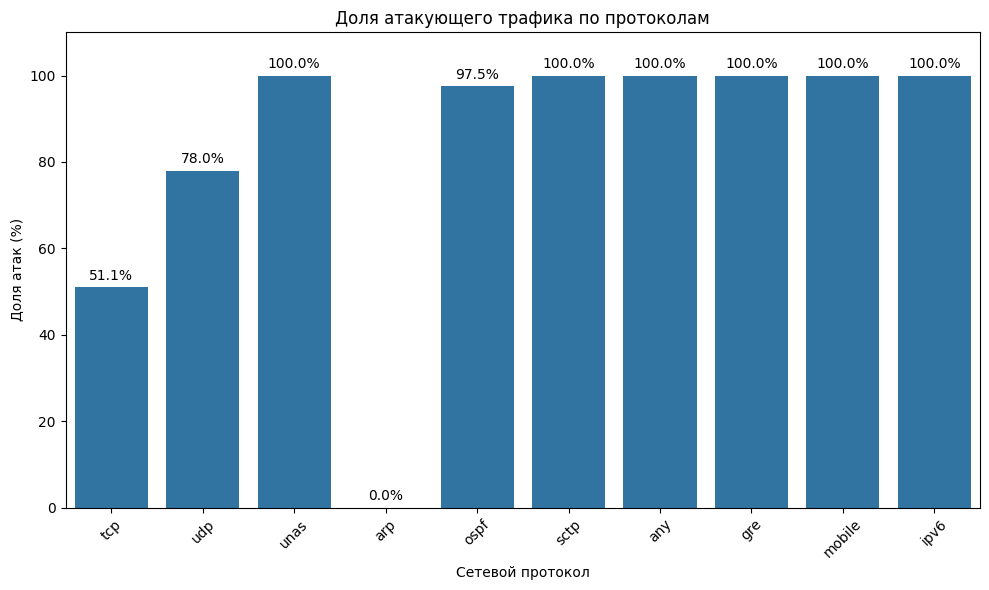

In [7]:

# Определяем 10 наиболее распространённых протоколов
top_protocols = df["proto"].value_counts().head(10).index

# Оставляем записи только с этими протоколами
proto_df = df[df["proto"].isin(top_protocols)]

# Подсчитываем количество записей и атак
proto_stats = proto_df.groupby("proto")["label"].agg(
    total="count",
    attacks="sum"
)

# Рассчитываем процент атак для каждого протокола
proto_stats["attack_percent"] = (
    proto_stats["attacks"] / proto_stats["total"] * 100
).round(2)

# Сортируем по общему количеству записей
proto_stats = proto_stats.sort_values(
    "total", ascending=False
)

display(proto_stats)

# Строим график
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=proto_stats.reset_index(),
    x="proto",
    y="attack_percent"
)

ax.set_title("Доля атакующего трафика по протоколам")
ax.set_xlabel("Сетевой протокол")
ax.set_ylabel("Доля атак (%)")

plt.ylim(0, 110)
plt.xticks(rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



**Выводы по анализу сетевых протоколов:**

Анализ десяти наиболее распространённых значений признака `proto` показал, что основную часть исследуемого трафика составляют TCP (79 946 записей) и UDP (63 283 записи).

Доля атакующего трафика для TCP составляет 51,07%, для UDP – 78,00%. Это свидетельствует о различиях в распределении целевой переменной между протоколами в исследуемой выборке.

Особого внимания заслуживают протоколы `unas`, `sctp`, `gre` и некоторые другие, для которых доля атак достигает 100%. В то же время все 2 859 записей с протоколом `arp` относятся к нормальному трафику.

Подобные зависимости могут быть обусловлены особенностями формирования лабораторного набора данных и не должны интерпретироваться как доказательство опасности или безопасности конкретных протоколов.

Для будущей ML-модели существует риск изучения ложных закономерностей, которые не будут воспроизводиться в реальном сетевом трафике.

Таким образом, признак `proto` потенциально информативен для классификации, но требует дополнительной проверки на устойчивость выявленных зависимостей и влияние смещения данных.



## 3.7. Анализ продолжительности сетевых соединений

Исследуем распределение продолжительности сетевых соединений (`dur`) отдельно для нормального и атакующего трафика.

Для каждого класса рассчитаем основные статистические характеристики и построим диаграмму размаха (Boxplot) и гистограмму (Histogram).

Поскольку распределение продолжительности сильно асимметрично, для визуализации используем логарифмическое преобразование `log(1 + dur)`.


,count,mean,median,max
label,,,,
0,56000,1.017177,0.038602,59.999989
1,119341,1.519969,0.000009,59.999046


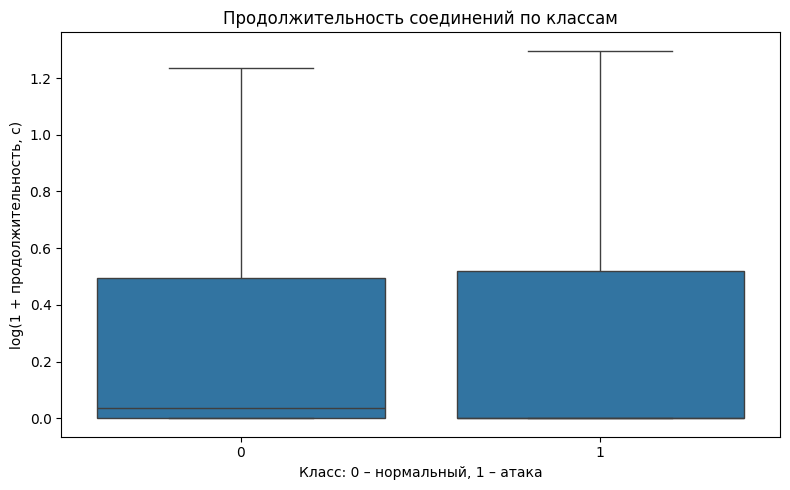

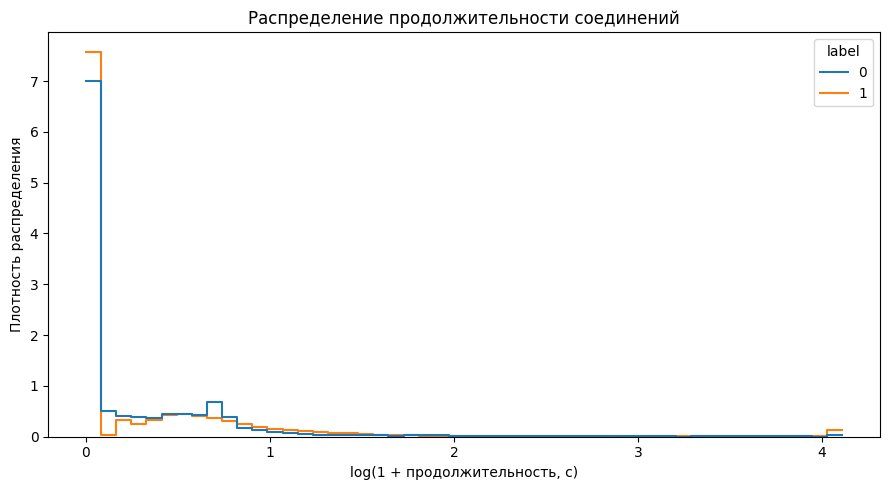

In [8]:

import numpy as np

# Статистика продолжительности для каждого класса
duration_stats = df.groupby("label")["dur"].agg(
    count="count",
    mean="mean",
    median="median",
    max="max"
)

display(duration_stats)

# Создаём отдельную таблицу для визуализации
duration_df = df[["label", "dur"]].copy()

# Логарифмическое преобразование
duration_df["log_duration"] = np.log1p(duration_df["dur"])

# График 1. Диаграмма размаха
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=duration_df,
    x="label",
    y="log_duration",
    showfliers=False
)

plt.title("Продолжительность соединений по классам")
plt.xlabel("Класс: 0 – нормальный, 1 – атака")
plt.ylabel("log(1 + продолжительность, с)")
plt.tight_layout()
plt.show()

# График 2. Распределение продолжительности
plt.figure(figsize=(9, 5))

sns.histplot(
    data=duration_df,
    x="log_duration",
    hue="label",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Распределение продолжительности соединений")
plt.xlabel("log(1 + продолжительность, с)")
plt.ylabel("Плотность распределения")
plt.tight_layout()
plt.show()



**Выводы по анализу продолжительности сетевых соединений:**

Анализ признака `dur` выявил существенные различия между распределениями продолжительности нормальных и атакующих соединений.

Средняя продолжительность нормального трафика составляет 1,017 секунды, атакующего – 1,520 секунды. Однако медианная продолжительность атакующего трафика значительно меньше: 0,000009 секунды против 0,038602 секунды у нормального.

Такое расхождение между средним и медианой указывает на выраженную асимметрию распределений. Значительная часть соединений имеет малую продолжительность, однако встречаются и длительные соединения, увеличивающие среднее значение.

Диаграмма размаха и гистограмма подтверждают концентрацию большого количества наблюдений около нуля. Логарифмическое преобразование позволило нагляднее сравнить распределения.

Признак `dur` потенциально полезен для будущей ML-модели, однако распределения классов существенно пересекаются, поэтому продолжительность соединения не может рассматриваться как самостоятельный надёжный индикатор атаки.

При последующей подготовке данных целесообразно рассмотреть логарифмическое преобразование признака и проверить устойчивость выявленных закономерностей на независимой выборке.



## 3.8. Анализ объёма передаваемых данных

Исследуем признаки `sbytes` и `dbytes`, характеризующие количество байтов, переданных в прямом и обратном направлениях сетевого взаимодействия.

Сравним статистические характеристики нормального и атакующего трафика, а также построим визуализации медианных значений и распределений объёмов данных.

Для отображения распределений используем логарифмическое преобразование `log(1 + x)`, позволяющее уменьшить влияние экстремально больших значений.


Статистика переданных байтов:


sbytes                      dbytes                  
           mean  median       max      mean  median       max
label                                                        
0       4105.70  1470.0    338718  31049.46  1112.0   2249492
1      11068.66   200.0  12965233   7364.46     0.0  14655550

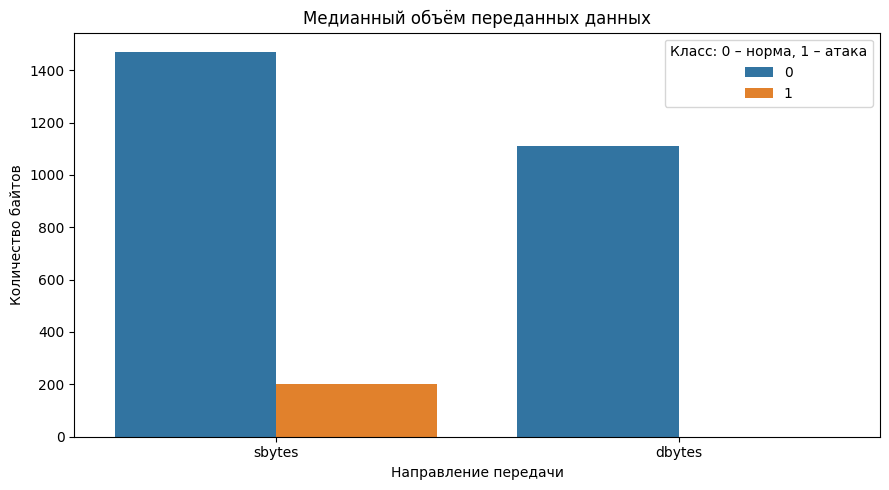

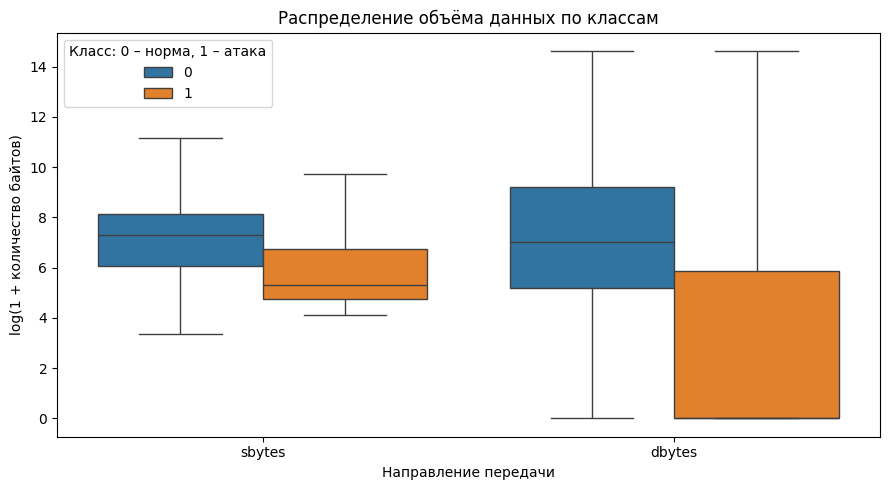

In [9]:

# Статистика объёмов данных по классам
byte_stats = df.groupby("label")[["sbytes", "dbytes"]].agg(
    ["mean", "median", "max"]
)

print("Статистика переданных байтов:")
display(byte_stats.round(2))

# Подготовка медианных значений для графика
byte_medians = df.groupby("label")[["sbytes", "dbytes"]].median().reset_index()

byte_medians_long = byte_medians.melt(
    id_vars="label",
    var_name="direction",
    value_name="median_bytes"
)

# График 1. Сравнение медианных значений
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=byte_medians_long,
    x="direction",
    y="median_bytes",
    hue="label"
)

ax.set_title("Медианный объём переданных данных")
ax.set_xlabel("Направление передачи")
ax.set_ylabel("Количество байтов")
ax.legend(title="Класс: 0 – норма, 1 – атака")

plt.tight_layout()
plt.show()

# Подготовка данных для второго графика
byte_plot = df[["label", "sbytes", "dbytes"]].melt(
    id_vars="label",
    var_name="direction",
    value_name="bytes"
)

byte_plot["log_bytes"] = np.log1p(byte_plot["bytes"])

# График 2. Диаграмма размаха
plt.figure(figsize=(9, 5))

ax = sns.boxplot(
    data=byte_plot,
    x="direction",
    y="log_bytes",
    hue="label",
    showfliers=False
)

ax.set_title("Распределение объёма данных по классам")
ax.set_xlabel("Направление передачи")
ax.set_ylabel("log(1 + количество байтов)")
ax.legend(title="Класс: 0 – норма, 1 – атака")

plt.tight_layout()
plt.show()



**Выводы по анализу объёма передаваемых данных:**

Анализ признаков `sbytes` и `dbytes` выявил существенные различия между нормальным и атакующим сетевым трафиком.

Медианный объём данных, переданных источником (`sbytes`), составляет 1 470 байт для нормальных соединений и 200 байт для атакующих. При этом среднее значение `sbytes` у атакующего трафика значительно выше – 11 068,66 байта против 4 105,70 байта у нормального.

Подобное расхождение между средним и медианой свидетельствует о выраженной асимметрии распределения и наличии соединений с экстремально большими объёмами передачи данных.

Особого внимания заслуживает признак `dbytes`: его медиана у атакующего трафика равна нулю, тогда как у нормального составляет 1 112 байт. Это означает, что не менее половины атакующих записей характеризуются отсутствием зарегистрированного объёма данных в обратном направлении.

Такая особенность может быть связана с характером сетевых взаимодействий или спецификой формирования лабораторного датасета и требует дополнительной проверки.

Диаграммы размаха показывают, что распределения нормального и атакующего трафика пересекаются. Следовательно, исследуемые признаки потенциально полезны для классификации, но не позволяют однозначно определить атаку по отдельному значению.

При дальнейшей предобработке целесообразно рассмотреть логарифмическое преобразование числовых признаков и дополнительное исследование соединений с `dbytes = 0`.



## 3.9. Корреляционный анализ сетевых признаков

Для исследования взаимосвязей между числовыми характеристиками сетевого трафика построим корреляционную матрицу.

Используем коэффициент корреляции Спирмена (Spearman Correlation), поскольку ранее были обнаружены асимметричные распределения и экстремальные значения числовых признаков.

Рассмотрим продолжительность соединения, количество пакетов и байтов, интенсивность передачи данных, значения TTL и целевую переменную `label`.

Визуализацию выполним с помощью тепловой карты (Heatmap).


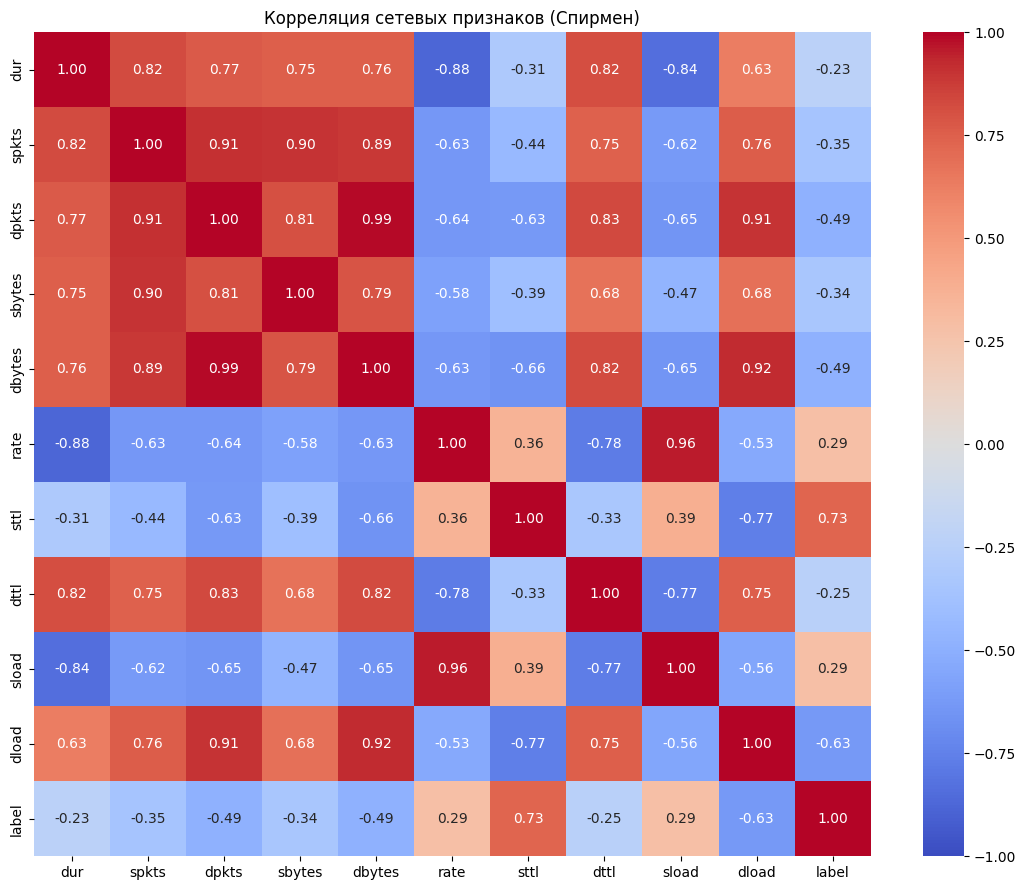

Корреляция признаков с label:


,label
sttl,0.732
dload,-0.626
dbytes,-0.491
dpkts,-0.485
spkts,-0.354
sbytes,-0.336
sload,0.288
rate,0.287
dttl,-0.249
dur,-0.230


In [10]:

# Выбираем числовые признаки для анализа
features = [
    "dur", "spkts", "dpkts",
    "sbytes", "dbytes", "rate",
    "sttl", "dttl", "sload", "dload",
    "label"
]

# Рассчитываем корреляцию Спирмена
corr_matrix = df[features].corr(method="spearman")

# Строим тепловую карту
plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Корреляция сетевых признаков (Спирмен)")
plt.tight_layout()
plt.show()

# Выводим связь признаков с целевой переменной
print("Корреляция признаков с label:")

label_corr = corr_matrix["label"].drop("label")
display(label_corr.reindex(
    label_corr.abs().sort_values(ascending=False).index
).round(3))



**Выводы по корреляционному анализу:**

Корреляционный анализ Спирмена позволил выявить статистические взаимосвязи между числовыми характеристиками сетевого трафика и целевой переменной `label`.

Наиболее выраженная положительная корреляция с целевой переменной обнаружена у признака `sttl` (+0,732). Это свидетельствует о существенной статистической связи между значениями TTL источника и принадлежностью записи к классу атаки.

Однако подобная зависимость может быть обусловлена особенностями формирования лабораторного датасета, а не универсальными характеристиками атакующего трафика. Поэтому признак `sttl` требует дополнительного исследования.

Отрицательная корреляция наблюдается у признаков `dload` (−0,626), `dbytes` (−0,491) и `dpkts` (−0,485). Это согласуется с ранее выявленной тенденцией к небольшим объёмам ответного трафика у значительной части атакующих соединений.

Также обнаружены сильные корреляции между отдельными сетевыми характеристиками: `dpkts` и `dbytes` (+0,99), `rate` и `sload` (+0,96), `spkts` и `sbytes` (+0,90). Это может свидетельствовать о частичной избыточности информации в наборе признаков.

При последующей подготовке данных целесообразно исследовать влияние сильно коррелирующих признаков на качество модели и проверить устойчивость выявленных зависимостей на независимых данных.

Корреляция не доказывает причинно-следственную связь, поэтому полученные результаты не следует интерпретировать как универсальные признаки сетевых атак.



## 3.10. Исследование потенциальных проблем датасета

### 3.10.1. Проверка зависимости TTL от целевой переменной

Ранее корреляционный анализ выявил сильную положительную связь между признаком `sttl` и целевой переменной `label` (+0,732).

Проверим, как распределяются значения TTL источника между нормальным и атакующим трафиком.

Цель анализа – выявить возможные закономерности, обусловленные особенностями формирования лабораторного датасета, которые могут ухудшать обобщающую способность будущей модели.


Количество уникальных значений sttl:
11

12 наиболее распространённых значений TTL:


,total,attacks,normal,attack_percent
sttl,,,,
254,114743,103513,11230,90.21
31,39455,0,39455,0.00
62,17681,15514,2167,87.74
0,3162,303,2859,9.58
64,181,0,181,0.00
1,64,0,64,0.00
63,32,0,32,0.00
255,13,11,2,84.62
60,6,0,6,0.00


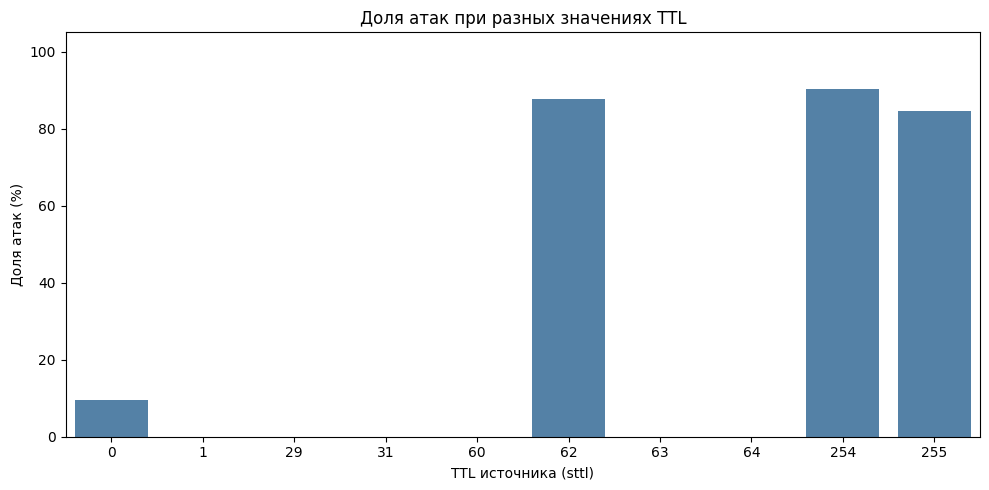

In [11]:

# Группируем записи по значениям TTL источника
ttl_stats = df.groupby("sttl")["label"].agg(
    total="count",
    attacks="sum"
)

# Вычисляем количество нормальных соединений
ttl_stats["normal"] = (
    ttl_stats["total"] - ttl_stats["attacks"]
)

# Рассчитываем долю атак для каждого TTL
ttl_stats["attack_percent"] = (
    ttl_stats["attacks"] / ttl_stats["total"] * 100
).round(2)

# Сортируем по количеству соединений
ttl_stats = ttl_stats.sort_values(
    "total", ascending=False
)

print("Количество уникальных значений sttl:")
print(df["sttl"].nunique())

print("\n12 наиболее распространённых значений TTL:")
display(ttl_stats.head(12))

# Выбираем 10 наиболее распространённых значений
top_ttl = ttl_stats.head(10).reset_index()

# Строим график
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=top_ttl,
    x="sttl",
    y="attack_percent",
    color="steelblue"
)

ax.set_title("Доля атак при разных значениях TTL")
ax.set_xlabel("TTL источника (sttl)")
ax.set_ylabel("Доля атак (%)")

plt.ylim(0, 105)
plt.tight_layout()
plt.show()



**Выводы по анализу признака `sttl`:**

Анализ показал, что в обучающей выборке UNSW-NB15 присутствует всего 11 уникальных значений TTL источника (`sttl`).

Наиболее распространённым является значение `sttl = 254`, встречающееся в 114 743 записях. Из них 90,21% относятся к атакующему трафику.

Особого внимания заслуживает значение `sttl = 31`: все 39 455 записей с таким значением относятся к нормальному трафику. При `sttl = 62` доля атак составляет 87,74%.

Полученные результаты подтверждают ранее обнаруженную сильную корреляцию между `sttl` и целевой переменной `label` (+0,732).

Подобные зависимости могут быть связаны с особенностями лабораторной генерации трафика, например различиями в сетевых настройках, начальных значениях TTL или маршрутах источников нормального и атакующего трафика.

Существует риск, что будущая модель будет использовать эти закономерности вместо более устойчивых признаков сетевых атак.

Поэтому признак `sttl` требует дополнительной проверки. При последующем обучении целесообразно сравнить качество моделей с использованием этого признака и без него, а также оценить их на независимых данных.



### 3.10.2. Анализ повторяющихся записей

Ранее было обнаружено 67 601 повторение после исключения уникального идентификатора `id`.

Для дополнительного исследования определим количество и долю повторных записей отдельно для нормального и атакующего трафика, а также рассмотрим распределение повторов по категориям атак.

Это позволит оценить потенциальное влияние повторяющихся записей на последующее обучение и тестирование ML-модели.


In [12]:

# Исключаем идентификатор записи
data_no_id = df.drop(columns=["id"])

# Находим повторные записи
duplicate_mask = data_no_id.duplicated()

# Общее количество повторений
print("Количество повторений:")
print(duplicate_mask.sum())

# Количество повторений по классам
duplicate_stats = pd.DataFrame({
    "Всего записей": df["label"].value_counts().sort_index(),
    "Повторений": df.loc[
        duplicate_mask, "label"
    ].value_counts().reindex([0, 1], fill_value=0)
})

# Рассчитываем процент повторений
duplicate_stats["Доля повторений (%)"] = (
    duplicate_stats["Повторений"] /
    duplicate_stats["Всего записей"] * 100
).round(2)

print("\nПовторения по классам:")
display(duplicate_stats)

# Исследуем повторения среди категорий атак
print("\nПовторения по категориям атак:")

attack_duplicates = df.loc[
    duplicate_mask & (df["label"] == 1),
    "attack_cat"
].value_counts()

display(attack_duplicates.to_frame("Повторений"))


Количество повторений:
67601

Повторения по классам:


,Всего записей,Повторений,Доля повторений (%)
label,,,
0,56000,4110,7.34
1,119341,63491,53.20



Повторения по категориям атак:


,Повторений
attack_cat,
Generic,35819
Exploits,13549
DoS,8458
Reconnaissance,2969
Fuzzers,2034
Analysis,406
Backdoor,211
Shellcode,42
Worms,3


**Выводы по анализу повторяющихся записей:**

Дополнительное исследование показало, что из 67 601 повторения, обнаруженного после исключения столбца `id`, 63 491 относятся к атакующему трафику и только 4 110 – к нормальному.

Доля повторений среди атакующего трафика составляет 53,20%, тогда как среди нормального – 7,34%. Таким образом, повторяющиеся записи распределены между классами крайне неравномерно.

Наибольшее количество повторений обнаружено в категориях `Generic` (35 819), `Exploits` (13 549) и `DoS` (8 458).

Если оставить только по одному экземпляру каждой совпадающей записи без учёта `id`, количество наблюдений сократится до 107 740, а доля атакующего трафика – приблизительно до 51,84%.

Это показывает, что повторяющиеся записи существенно влияют на распределение классов в исследуемой выборке.

Однако одинаковые характеристики не обязательно свидетельствуют об ошибке, поскольку разные сетевые взаимодействия могут иметь совпадающие значения признаков.

При последующей разработке ML-модели необходимо исследовать причины повторений и исключить попадание одинаковых записей одновременно в обучающую и тестовую выборки, поскольку это может привести к завышенной оценке качества классификатора.

На этапе EDA исходные данные оставлены без изменений.


## 3.11. Рекомендации по предобработке данных

На основании проведённого разведочного анализа сформулированы рекомендации по подготовке датасета UNSW-NB15 к последующему обучению модели машинного обучения.

**1. Обработка повторяющихся записей.**

В наборе данных обнаружено 67 601 повторение после исключения идентификатора `id`. Необходимо дополнительно исследовать происхождение повторений и определить целесообразность их удаления.

При формировании обучающей и тестовой выборок важно предотвращать попадание одинаковых записей в обе выборки, поскольку это может привести к завышенной оценке качества модели.

**2. Исключение служебных признаков и предотвращение утечки данных.**

Столбец `id` является идентификатором записи и не должен использоваться как входной признак классификатора.

Столбец `attack_cat` содержит категорию атаки и непосредственно связан с целевой переменной `label`. Его использование при бинарной классификации может привести к утечке информации о правильном ответе.

Целевая переменная `label` также исключается из входных признаков и используется только как правильная метка класса.

**3. Кодирование категориальных признаков.**

Столбцы `proto`, `service` и `state` содержат категориальные значения, которые необходимо преобразовать в числовое представление.

Для этого можно использовать One-Hot Encoding – метод кодирования, создающий отдельные бинарные признаки для категорий.

Специальные значения, например `"-"` в столбце `service`, требуют отдельной проверки и корректной интерпретации.

**4. Преобразование числовых признаков.**

Анализ показал выраженную асимметрию распределений `dur`, `sbytes` и `dbytes`.

Для таких неотрицательных признаков целесообразно рассмотреть логарифмическое преобразование `log(1 + x)`, уменьшающее влияние экстремально больших значений.

При использовании алгоритмов, чувствительных к масштабу признаков, также может потребоваться стандартизация или нормализация.

**5. Проверка подозрительных зависимостей.**

Признак `sttl` демонстрирует сильную корреляцию с целевой переменной (+0,732). Некоторые значения сетевых протоколов также практически однозначно связаны с определённым классом в исследуемой выборке.

Эти закономерности могут быть обусловлены особенностями лабораторного формирования данных.

Рекомендуется сравнить качество моделей с использованием `sttl` и без него, а также проверить устойчивость зависимости от сетевых протоколов на независимых данных.

**6. Учёт дисбаланса классов.**

В обучающей выборке 68,06% записей относятся к атакам, а 31,94% – к нормальному трафику.

При обучении необходимо учитывать дисбаланс классов. Для оценки качества рекомендуется использовать Recall, Precision и FPR, а также отдельно анализировать полноту обнаружения различных категорий атак.

**7. Разделение данных и проверка обобщающей способности.**

Для итоговой оценки модели следует использовать независимую тестовую выборку. UNSW-NB15 предоставляет отдельный тестовый файл, который может использоваться для этих целей после проверки совместимости признаков и возможных пересечений записей.

Все преобразования, требующие оценки параметров по данным, должны настраиваться исключительно на обучающей выборке, чтобы предотвратить утечку информации.

Поскольку UNSW-NB15 получен в лабораторной среде, высокое качество на данном датасете не будет гарантировать аналогичную эффективность обнаружения атак в реальной корпоративной сети.



# 4. Итоговые выводы

В ходе выполнения работы была сформулирована задача обнаружения сетевых атак с использованием машинного обучения, выбраны метрики качества будущего классификатора и проведён разведочный анализ данных (EDA) на основе UNSW-NB15.

**Основные результаты исследования:**

**1. Структура и качество данных.**

Исследуемая обучающая выборка содержит 175 341 запись и 45 столбцов. Пропущенных значений (`NaN`) не обнаружено. Однако после исключения идентификатора `id` выявлено 67 601 повторение, что составляет приблизительно 38,6% всех записей.

**2. Распределение классов и категорий атак.**

Атакующий трафик составляет 68,06% выборки, нормальный – 31,94%. Среди категорий атак преобладают `Generic` (33,52%) и `Exploits` (27,98%), тогда как категория `Worms` представлена всего 130 записями.

Такое распределение необходимо учитывать при последующем обучении и оценке качества модели.

**3. Анализ сетевых характеристик.**

Исследование продолжительности соединений (`dur`) и объёмов передаваемых данных (`sbytes`, `dbytes`) выявило существенные различия между нормальным и атакующим трафиком.

Для ряда числовых признаков характерны асимметричные распределения и экстремально большие значения. При этом распределения двух классов пересекаются, поэтому отдельные характеристики не могут считаться самостоятельными надёжными индикаторами атаки.

**4. Корреляционный анализ.**

Наиболее выраженная положительная корреляция с целевой переменной обнаружена у признака `sttl` (+0,732), а отрицательная – у `dload` (−0,626).

Также выявлены сильные взаимосвязи между отдельными сетевыми характеристиками, например `dpkts` и `dbytes` (+0,99), что указывает на возможную избыточность части признаков.

**5. Потенциальные проблемы и ограничения датасета.**

Особое внимание было уделено необычным закономерностям в данных.

При значении `sttl = 31` все 39 455 записей относятся к нормальному трафику, тогда как при `sttl = 254` доля атак составляет 90,21%.

Некоторые протоколы также представлены исключительно одним классом. Подобные зависимости могут быть обусловлены особенностями формирования лабораторного трафика и не должны автоматически переноситься на реальные корпоративные сети.

Кроме того, повторяющиеся записи распределены неравномерно: среди атакующего трафика их доля составляет 53,20%, среди нормального – 7,34%.

Это создаёт риск искажения результатов обучения и завышенной оценки качества модели при некорректном разделении данных.

**6. Рекомендации по дальнейшей работе.**

Перед обучением классификатора рекомендуется:

- Исключить `id` и `attack_cat` из входных признаков модели.
- Исследовать повторения и предотвратить пересечение одинаковых записей между обучающей и тестовой выборками.
- Закодировать категориальные признаки и рассмотреть преобразование числовых характеристик.
- Проверить устойчивость подозрительных зависимостей, особенно для `sttl` и `proto`.
- Оценивать будущую модель с помощью Recall, Precision и FPR.
- Использовать независимые тестовые данные для проверки обобщающей способности модели.

**Общий вывод.**

UNSW-NB15 подходит для изучения методов анализа сетевого трафика и разработки учебных моделей обнаружения вторжений. Однако проведённый EDA выявил ограничения, связанные с распределением классов, повторяющимися записями и зависимостью меток атак от отдельных сетевых характеристик.

Поэтому высокая точность будущего классификатора на данном наборе данных не будет сама по себе доказывать его эффективность в реальных условиях.

В рамках текущей работы обучение модели не проводилось. Полученные результаты формируют основу для последующей подготовки данных и разработки классификатора сетевых атак.
